# Enhancing Generative Models via Quantum Correlations — reproduction notebook

Gao, Anschuetz, Wang, Cirac, Lukin, *Phys. Rev. X* **12**, 021037 (2022),
[arXiv:2101.08354](https://arxiv.org/abs/2101.08354).

This notebook is the scientific entry point of the reproduction. It walks
through one question: **do quantum correlations make a sequence model
learn and generalise better than a classical model of the same size?** It
does so by reproducing the paper's experiments, then testing the paper's
explanation against fair classical baselines.

**How to read it.**

- **Live parts:** cells marked *live* recompute results from `lib/` in
  seconds to minutes. These are exact checks, a 3-seed training run and a
  small photonic model.
- **Stored parts:** cells marked *stored* load the full results (5,502
  run attempts: 12.5 h of sweep wall clock on 6 workers, about 62 h of
  summed per-run time) from curated files in `results/`.
- **Rerun after a fix:** a pre-handoff check found that the first BE
  implementation read the last site out with a trace instead of the sum
  over all traced paths (§3). The model was fixed and every affected sweep
  rerun; all stored results come from the rerun.
  These files were generated by the scripts in `utils/` from the run
  artifacts (`LOG.md` records every command).
- **Runtime:** a clean run of the whole notebook takes about 3 minutes on
  a laptop CPU.

**Labels used throughout.**

| Label | Meaning |
|---|---|
| *Faithful reproduction* | Paper protocol, paper hyperparameters, paper data (§6-7) |
| *Control* | A classical baseline added here to test the paper's explanation (§8-9) |
| *Robustness* | Variation of an unstated choice (§10) |
| *Extension* | Not in the paper: the photonic MerLin adaptation (§11) |

**Contents.**

1. Problem and claims
2. Data, metrics, protocol
3. The models in equations
4. Known-answer checks
5. Model walkthrough
6. Live experiment
7. Headline reproduction
8. Fair baselines
9. Controls and ablations
10. Robustness and uncertainty
11. Photonic assessment
12. Conclusion

In [1]:
# Setup: paths, imports, shared constants. Run from papers/quantum_correlations_generative_models.
import contextlib
import io
import itertools
import json
import math
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

PAPER_DIR = Path.cwd()
assert (PAPER_DIR / "lib" / "runner.py").exists(), (
    "Start Jupyter in papers/quantum_correlations_generative_models"
)
REPO_ROOT = PAPER_DIR.parents[1]
for path in (REPO_ROOT, PAPER_DIR.parent):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from runtime_lib.config import deep_update, load_config  # noqa: E402
from runtime_lib.dtypes import resolve_config_dtypes  # noqa: E402

from quantum_correlations_generative_models.lib import cluster_bbqc, runner, stabilizer  # noqa: E402
from quantum_correlations_generative_models.lib.basis_enhanced import (  # noqa: E402
    BasisEnhancedTwoGram,
    RiemannianMomentum,
    free_parameter_count,
    hmm_parameter_count,
    parameter_matched_hmm_bond_dim,
    unitarity_error,
)
from quantum_correlations_generative_models.lib.data import load_splits  # noqa: E402
from quantum_correlations_generative_models.lib.hmm import HiddenMarkovModel  # noqa: E402
from quantum_correlations_generative_models.lib.metrics import (  # noqa: E402
    empirical_entropy_bits_per_site,
    likelihood_ratio_threshold_bits,
    paper_kl_estimate_bits_per_site,
)

RESULTS = PAPER_DIR / "results"
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)

# One colour and marker per system, used in every figure.
STYLE = {
    "BE": {"color": "#eb6834", "marker": "x", "label": "BE: basis-enhanced 2-gram (paper)"},
    "B1": {"color": "#2a78d6", "marker": "o", "label": "B1: HMM, Baum-Welch, converged"},
    "B2": {"color": "#eda100", "marker": "s", "label": "B2: HMM, gradient-trained"},
    "B3": {"color": "#1baf7a", "marker": "^", "label": "B3: HMM, parameter-matched h'"},
    "B4": {"color": "#e87ba4", "marker": "D", "label": "B4: BE with real amplitudes"},
    "B5": {"color": "#6250d6", "marker": "v", "label": "B5: k-gram counting model"},
    "MerLin": {"color": "#008300", "marker": "P", "label": "MerLin adaptation (simulated)"},
}
ARMS = ["biofam", "promoter_gene_sequences", "spect_heart", "spect_heart_pooled"]
ARM_TITLE = {
    "biofam": "biofam (n=16, M=8)",
    "promoter_gene_sequences": "Promoters (n=57, M=4)",
    "spect_heart": "SPECT, standard split (as stated)",
    "spect_heart_pooled": "SPECT, pooled split (paper-inferred)",
}
ARM_CONFIG = {
    "biofam": "biofam",
    "promoter_gene_sequences": "promoters",
    "spect_heart": "spect",
    "spect_heart_pooled": "spect_pooled",
}


def config_for(name: str, **changes) -> dict:
    # defaults.json + configs/<name>.json + dotted overrides, as the shared runtime does.
    cfg = deep_update(
        load_config(PAPER_DIR / "configs" / "defaults.json"),
        load_config(PAPER_DIR / "configs" / f"{name}.json"),
    )
    for dotted, value in changes.items():
        node = cfg
        *parents, leaf = dotted.split("__")
        for key in parents:
            node = node[key]
        node[leaf] = value
    return resolve_config_dtypes(cfg)


print("torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

torch 2.14.1 | numpy 2.5.3 | pandas 3.0.5


## 1. Problem and claims

**Problem.** A Bayesian network over a sequence is a classical generative
model. Gao et al. show that Bayesian networks equal "Bayesian quantum
circuits" whose qubits are measured in the computational basis.
- **The quantum extension:** the minimal quantum extension lets each visible
  qubit be measured in any *local* basis. For sequences this gives a matrix
  product state, the *basis-enhanced 2-gram model* (BE).
- **Its memory:** BE carries a quantum memory of dimension $h$ (the bond
  dimension) from site to site.
- **Classical counterpart:** a hidden Markov model (HMM) with $h$ hidden
  states.

**Claims tested here** (claim IDs as in `LOG.md`):

| ID | Claim | Paper evidence | Tested in |
|---|---|---|---|
| C1 | Theorem 1: no classical k-gram with $k<\lfloor (n-1)/2\rfloor$ approximates a cluster-state BE model (GHZ nonlocality) | Proof, Fig. 2 | §4 |
| C2 | Theorem 2: some BE models need $D^{\Omega(\log D)}$ HMM states (contextuality) | Proof, Table I | §4 (ingredients only) |
| C3 | On real data, BE "learns better and generalizes better" than an HMM of the same $h$ on Promoters and SPECT; comparable on biofam | Fig. 7 | §7, §8 |
| C4 | The training gap is significant at more than 5σ (likelihood-ratio test) | Fig. 8 | §7, §9 |
| C5 | The separation persists in the mean over 10 trials | Fig. 13 | §8 |
| Sec. VI | The gap comes from complex amplitudes (quantum interference) | Text | §9 |

**Falsifiable research question.** *At matched resources, does BE assign a
higher likelihood to held-out sequences than classical sequence models?*

**What would weaken the claim:**
- an HMM trained to convergence matches BE;
- an HMM with as many free parameters as BE matches or beats it;
- tuning both models on validation data removes the gap;
- BE restricted to real amplitudes does as well, so the gap is not due to
  complex amplitudes.

Each of these is tested below.

## 2. Data, splits, metrics and evaluation protocol

The paper uses three public data sets, all reused here complete and in
their original form:
- **biofam:** Swiss life trajectories, 16 yearly states from 8 categories.
- **Promoter Gene Sequences:** 106 DNA sequences of 57 nucleotides; the
  class label is dropped.
- **SPECT Heart:** 23 binary features of cardiac images.

**Splits.**
- *biofam and Promoters:* the paper holds out "a quarter of the data" but
  does not say which, so the quarter is drawn with split seed 0.
- *SPECT:* the paper names the standard 80/187 split. Its plotted numbers,
  however, match a pooled 267-row split with a random quarter held out
  (calibrated in §2.1 and in `LOG.md`, R6). Both readings are run; they are
  labelled *standard (as stated)* and *pooled (paper-inferred)*.
- *Validation-tuned protocol (arm B):* 20% of the training pool is carved
  out as a validation set, drawn from a second permutation, so the **test
  sets are identical in both protocols**.

In [2]:
# live: load every split exactly as the experiments do.
rows = []
SPLITS = {}
for arm in ARMS:
    for protocol, suffix in (("A: paper protocol", "_original"), ("B: validation-tuned", "_val_original")):
        cfg = config_for(f"e5_fig7_{ARM_CONFIG[arm]}{suffix}")
        splits = load_splits(cfg)
        SPLITS[(arm, protocol[0])] = splits
        rows.append({
            "arm": arm, "protocol": protocol, "n": splits.sequence_length, "M": splits.alphabet_size,
            "train": len(splits.train), "validation": len(splits.validation), "test": len(splits.test),
            "test fraction": cfg["dataset"]["test_fraction"],
            "train entropy (bits/site)": empirical_entropy_bits_per_site(splits.train),
        })
data_table = pd.DataFrame(rows)
assert all(
    np.array_equal(SPLITS[(arm, "A")].test, SPLITS[(arm, "B")].test) for arm in ARMS
), "test sets must be identical in both protocols"
data_table

,arm,protocol,n,M,train,validation,test,test fraction,train entropy (bits/site)
0,biofam,A: paper protocol,16,8,1500,0,500,0.25,0.4869
1,biofam,B: validation-tuned,16,8,1200,300,500,0.25,0.4834
2,promoter_gene_sequences,A: paper protocol,57,4,80,0,26,0.25,0.1109
3,promoter_gene_sequences,B: validation-tuned,57,4,64,16,26,0.25,0.1053
4,spect_heart,A: paper protocol,23,2,80,0,187,NaN,0.2467
5,spect_heart,B: validation-tuned,23,2,64,16,187,NaN,0.2405
6,spect_heart_pooled,A: paper protocol,23,2,201,0,66,0.25,0.3114
7,spect_heart_pooled,B: validation-tuned,23,2,161,40,66,0.25,0.3006


### 2.1 Metric

Every model is a normalised distribution $p(x)$ over sequences
$x=(x_1,\dots,x_n)$. The primary metric is the **per-site negative
log-likelihood in bits**, where lower is better:

$$\mathrm{NLL}=-\frac{1}{N\,n}\sum_{x\in\text{split}}\log_2 p(x).$$

The paper plots a "stochastic estimate of the KL divergence (normalized by
the sequence length)" without saying what it subtracts. The calibration
below shows that it is

$$\mathrm{KL}_{\text{paper}} = \mathrm{NLL}-\frac{\log_2 N}{n},$$

the KL divergence from the uniform distribution over the $N$ evaluated rows
to the model.
- **Why the comparisons are unaffected:** for a fixed split the two metrics
  differ by a constant, so every difference between models is the same in
  both.
- **How it is checked:** at $h=1$ both models reduce to the same i.i.d.
  per-site marginal, which has a closed form. The cell below compares that
  closed form with the paper's $h=1$ points, read from a 300-dpi image of
  Fig. 7.

In [3]:
# live: closed-form h = 1 model (i.i.d. symbol marginal fitted on train) vs the paper's h = 1 points.
paper_values = json.loads((RESULTS / "paper_values_fig7_fig8.json").read_text())


def iid_nll_bits(train: np.ndarray, evaluate: np.ndarray, alphabet: int) -> float:
    marginal = np.bincount(train.ravel(), minlength=alphabet) / train.size
    return float(-np.log2(marginal[evaluate]).mean())


rows = []
for arm, paper_key in (("promoter_gene_sequences", "promoter_gene_sequences"),
                       ("spect_heart_pooled", "spect_heart"), ("spect_heart", "spect_heart"),
                       ("biofam", "biofam")):
    splits = SPLITS[(arm, "A")]
    for split in ("train", "test"):
        data = getattr(splits, split)
        nll = iid_nll_bits(splits.train, data, splits.alphabet_size)
        rows.append({
            "arm": arm, "split": split, "NLL (bits/site)": nll,
            "NLL - log2(N)/n": paper_kl_estimate_bits_per_site(nll, len(data), splits.sequence_length),
            "paper h=1 (BE)": paper_values["fig7_best_of_ten"][paper_key][split]["basis_enhanced"]["1"],
        })
calibration = pd.DataFrame(rows)
calibration["difference"] = calibration["NLL - log2(N)/n"] - calibration["paper h=1 (BE)"]
calibration

,arm,split,NLL (bits/site),NLL - log2(N)/n,paper h=1 (BE),difference
0,promoter_gene_sequences,train,1.9932,1.8823,1.887,-0.0047
1,promoter_gene_sequences,test,1.9954,1.9130,1.908,0.0050
2,spect_heart_pooled,train,0.9130,0.5804,0.581,-0.0006
3,spect_heart_pooled,test,0.9313,0.6685,0.667,0.0015
4,spect_heart,train,0.7816,0.5067,0.581,-0.0743
5,spect_heart,test,1.0292,0.7011,0.667,0.0341
6,biofam,train,2.0161,1.3566,1.400,-0.0434
7,biofam,test,1.9999,1.4395,1.440,-0.0005


**Observation.**
- On Promoters and the pooled SPECT split, the closed form matches the
  paper's $h=1$ points to within 0.005 bits/site (pooled SPECT within
  0.002). The paper's own BE and HMM points at $h=1$ differ by up to 0.002.
- Only $\mathrm{NLL}-\log_2 N/n$ can be negative, as the paper's biofam
  training curve is (§7).
- On the *standard* SPECT split it misses by about 0.07: the paper's
  numbers come from a different split.
- On biofam it matches on test (0.0005), but misses by about 0.04 on
  train, for both models alike (a data offset, `LOG.md` R12).

**Inference.** The metric calibration is reliable, and the SPECT numbers in
the paper belong to the pooled split.

**Remaining uncertainty.** The calibration rests on plot readings
(precision ±0.002-0.02).

**Claim impact.** None by itself. It makes the paper-vs-reproduction
comparison in §7 meaningful.

### 2.2 Evaluation protocol (fixed before any comparison run)

| | Arm A: paper protocol | Arm B: validation-tuned |
|---|---|---|
| Training data | full training pool | training pool minus 20% validation |
| Checkpoint | final epoch / final EM iteration | epoch or EM iteration with the lowest **validation** NLL |
| Hyperparameters | paper values (BE: $\alpha$ = 1e-3 biofam / 1e-2 others, $\beta$ = 0.5, 75 / 150 epochs, batch 8) | same grid and budget for every model, chosen on validation only |
| Seeds | 0-9 per (model, h) | 0-9 per (model, h) |
| Test set | never used for any choice | never used for any choice |

**Aggregation:** mean and SEM over the 10 seeds. Best-of-10 is also shown
because the paper plots it.

**Separation rule** (declared in `LOG.md` before the runs): $X$ beats $Y$
at the same $h$ (or at the matched size $h'$ for B3) if

$$\overline{\mathrm{NLL}}_Y-\overline{\mathrm{NLL}}_X > 2\sqrt{\mathrm{SEM}_X^2+\mathrm{SEM}_Y^2}.$$

Anything less is a tie.

**Claim-level rule:** a claim is *SUPPORTED* if the advantage holds at
$\ge 9$ of the 11 values $h=2..12$, *PARTIALLY_SUPPORTED* at 3-8, and
*UNSUPPORTED* at $\le 2$.

## 3. The models in equations

Equations come from the paper's page images (Fig. 6a, Eqs. 19-26,
pp. 12-13). Where the paper is ambiguous, the reading used is marked.

**Classical HMM** ($h$ hidden states). With initial distribution $\pi$,
transitions $A$ and emissions $e$:

$$p(x)=\sum_{j_1..j_n}\pi_{j_1}\,e_{j_1x_1}\prod_{i\ge2}A_{j_{i-1}j_i}\,e_{j_ix_i},$$

It has $h(h+M-1)-1$ free parameters and is trained by Baum-Welch (EM).

**Basis-enhanced 2-gram (BE)**, our reading of Fig. 6a (`LOG.md` R2). Each
site has a top wire of dimension $h$ and a bottom wire of dimension $M$:
- a prior unitary $U_p$ prepares the first top wire;
- a controlled unitary $U_t^{(j)}$ prepares the next top wire, conditioned
  on the previous one being in state $j$;
- an output unitary $U_o$ acts on (top, bottom);
- the bottom wire is measured, giving the symbol $x_i$;
- every top wire leaving $U_o$, the last one included, is traced out.
  So at the last site $p$ sums *all* entries of the contracted
  $\rho\,G_{x_n}$, not only its trace (Figs. 6a, 6b, 12a). An earlier
  version of the code took the trace; §4 checks the fixed code against
  the formula below by brute force.

$$\Psi(x,t)=\sum_{j}U_p[j_1,0]\prod_{i\ge2}U_t^{(j_{i-1})}[j_i,0]\prod_i U_o[(t_i,x_i),(j_i,0)],\qquad p(x)=\sum_t|\Psi(x,t)|^2 .$$

- **Normalisation:** $p$ is normalised whenever all matrices are unitary.
- **Contains the HMM:** with non-negative real amplitudes
  $U_t^{(j)}[a,0]=\sqrt{A_{ja}}$ and
  $U_o[(j,x),(j,0)]=\sqrt{e_{jx}}$, BE *is* the HMM. So BE contains the
  HMM class, and the interesting part is the complex interference between
  hidden paths.
- **Parameter count:** $(M+1)h^2-2$ free real parameters (the rank of the
  Jacobian of $p$ with respect to the unitaries), 2-6 times the HMM's at
  the same $h$. This matters in §8.

**Training** (Eqs. 19-26):
- *Loss:* minibatch NLL, $\mathcal L=-\frac1K\sum_{x\in\text{batch}}\ln p(x)$,
  with $K=8$.
- *Optimiser:* Riemannian momentum descent on the unitary group,

$$v\leftarrow\beta v+\alpha G,\qquad U\leftarrow \exp\!\big(-(vU^\dagger-Uv^\dagger)\big)\,U ,$$

  where $G = 2\,\partial\mathcal L/\partial\bar U$.
- *Sign:* the printed Eq. 26 has the opposite sign inside the exponential,
  which ascends with this gradient convention. The descent form of the
  cited reference (Abrudan et al.) is used; §4 checks that it descends.

**Theorem 1 model** (Fig. 2, Eqs. 4-5, p. 7): a 1D cluster state whose
physical qubits are measured in $X$ or $Y$ according to a classical bit
$b$. Three chosen pairs then carry a GHZ-type distribution:

$$q(b_1s_1b_2s_2b_3s_3)\;\propto\;1+\mathrm{Re}\!\left[i^{\,b_1+b_2+b_3}\right](-1)^{s_1+s_2+s_3}.$$

Eq. 4 is printed without "Re"; the literal expression is complex for odd
$b_1+b_2+b_3$, and the real part is the Born rule (§4 checks it exactly).

## 4. Known-answer checks (live)

Before trusting any learning curve, the components are checked against
answers known exactly. These checks validate components; they are not the
end-to-end reproduction.

In [4]:
# live: Theorem 1 (Fig. 2a) and App. F. The ML k-gram fit of order k to the exact model distribution
# must miss the support for every k below the threshold; a 6-state hidden process must equal the model.
rows = []
for num_pairs in (5, 7, 9):
    target = cluster_bbqc.exact_distribution(num_pairs)
    fits = [cluster_bbqc.compare_distributions(cluster_bbqc.ml_kgram(target, k), target)
            for k in range(1, num_pairs + 1)]
    minimal = next(k for k, fit in enumerate(fits, start=1) if fit["support_equal"])
    rows.append({
        "pairs n": num_pairs,
        "paper threshold floor((n-1)/2)": (num_pairs - 1) // 2,
        "smallest ML k-gram order with correct support": minimal,
        "mass outside support at k = n-1": fits[num_pairs - 2]["model_mass_outside_target_support"],
        "App. F 6-state process, max |difference|": float(
            np.abs(cluster_bbqc.hidden_process_distribution(num_pairs) - target).max()),
    })
transfer = cluster_bbqc.exact_distribution(5)
conditional = cluster_bbqc.ghz_conditional(transfer, [0, 2, 4])
print("Eq. 4 with Re[...]: max |difference| =", float(np.abs(conditional - cluster_bbqc.eq4_reference(True)).max()))
print("Eq. 5 support violations:", cluster_bbqc.eq5_violations(conditional))
print("statevector cross-check (10 qubits):",
      float(np.abs(transfer - cluster_bbqc.statevector_distribution(5)).max()))
pd.DataFrame(rows)

Eq. 4 with Re[...]: max |difference| = 3.469446951953614e-18
Eq. 5 support violations: 0
statevector cross-check (10 qubits): 6.505213034913027e-19


,pairs n,paper threshold floor((n-1)/2),smallest ML k-gram order with correct support,mass outside support at k = n-1,"App. F 6-state process, max |difference|"
0,5,2,5,0.1719,6.5052e-19
1,7,3,7,0.1680,8.1315e-20
2,9,4,9,0.1670,7.6233e-21


In [5]:
# live: App. E robust bound and the Theorem 2 ingredients (Mermin-Peres square, Lemma 1 counts).
l1 = [{"pairs n": n, "order k": k,
       "l1(ML k-gram, model)": cluster_bbqc.compare_distributions(
           cluster_bbqc.ml_kgram(cluster_bbqc.exact_distribution(n), k),
           cluster_bbqc.exact_distribution(n))["l1_distance"],
       "App. E bound": 1 / 288} for n in (7, 11) for k in (1, 2, 3)]
square = stabilizer.mermin_peres_checks()
counts = [{"qubits": q, "enumerated stabilizer states": stabilizer.enumerate_stabilizer_states(q),
           "Aaronson-Gottesman formula": stabilizer.stabilizer_count_formula(q)} for q in (1, 2, 3)]
print("Mermin-Peres column product signs:", square["column_product_signs"])
print("LHV maximum success for the GHZ game (Lemma 6):", stabilizer.ghz_lhv_max_success())
display(pd.DataFrame(l1))
pd.DataFrame(counts)

Mermin-Peres column product signs: [1.0, 1.0, -1.0]
LHV maximum success for the GHZ game (Lemma 6): 0.875


,pairs n,order k,"l1(ML k-gram, model)",App. E bound
0,7,1,0.3359,0.0035
1,7,2,0.3359,0.0035
2,7,3,0.3359,0.0035
3,11,1,0.3335,0.0035
4,11,2,0.3335,0.0035
5,11,3,0.3335,0.0035


,qubits,enumerated stabilizer states,Aaronson-Gottesman formula
0,1,6,6
1,2,60,60
2,3,1080,1080


In [6]:
# live: BE contains the HMM exactly, is normalised, and the Riemannian step descends and stays unitary.
generator = torch.Generator().manual_seed(0)
h, M, n = 3, 2, 6
all_sequences = torch.tensor(list(itertools.product(range(M), repeat=n)))
hmm = HiddenMarkovModel.random(h, M, generator)
embedded = BasisEnhancedTwoGram(h, M, generator)
embedded.from_hmm(hmm.initial, hmm.transition, hmm.emission)
with torch.no_grad():
    difference = (embedded.log_prob(all_sequences) - hmm.log_prob(all_sequences)).abs().max().item()
    random_model = BasisEnhancedTwoGram(h, M, torch.Generator().manual_seed(1))
    total = random_model.log_prob(all_sequences).exp().sum().item()
print(f"BE built from an HMM vs the HMM, max |log p difference| over all {M}^{n} sequences: {difference:.1e}")
print(f"random BE model, total probability over all sequences: {total:.15f}")

batch = all_sequences[torch.randperm(len(all_sequences), generator=generator)[:16]]
optimiser = RiemannianMomentum(random_model.unitary_parameters(), lr=0.01, momentum=0.5)
before = -random_model.log_prob(batch).mean()
before.backward()
optimiser.step()
optimiser.zero_grad()
with torch.no_grad():
    after = -random_model.log_prob(batch).mean()
print(f"one Riemannian step: loss {before.item():.6f} -> {after.item():.6f}; "
      f"unitarity error {unitarity_error(random_model):.1e}")


def amplitude_formula_probability(model, sequence):
    # p(x) = sum_t |Psi(x, t)|^2 with explicit sums over hidden paths j and traced outputs t (§3).
    prior, transfer, output = model.prior.detach(), model.transfer.detach(), model.output.detach()
    size, alphabet, length = model.bond_dim, model.alphabet_size, len(sequence)
    total = 0.0
    for traced in itertools.product(range(size), repeat=length):
        amplitude = 0.0
        for hidden in itertools.product(range(size), repeat=length):
            term = prior[hidden[0], 0]
            for site in range(1, length):
                term = term * transfer[hidden[site - 1]][hidden[site], 0]
            for site in range(length):
                term = term * output[traced[site] * alphabet + sequence[site], hidden[site] * alphabet]
            amplitude = amplitude + term
        total += float(abs(amplitude) ** 2)
    return total


small = BasisEnhancedTwoGram(2, 3, torch.Generator().manual_seed(2))
short = torch.tensor(list(itertools.product(range(3), repeat=4)))
with torch.no_grad():
    contracted = small.log_prob(short).exp()
brute = torch.tensor([amplitude_formula_probability(small, s) for s in short.tolist()], dtype=torch.float64)
print(f"BE likelihood vs the explicit amplitude formula (h = 2, M = 3, all 3^4 sequences): "
      f"max |difference| {(contracted - brute).abs().max().item():.1e}")

BE built from an HMM vs the HMM, max |log p difference| over all 2^6 sequences: 1.8e-15
random BE model, total probability over all sequences: 0.999999999999999
one Riemannian step: loss 4.712961 -> 4.640992; unitarity error 2.8e-14


BE likelihood vs the explicit amplitude formula (h = 2, M = 3, all 3^4 sequences): max |difference| 5.6e-17


**Observation.**
- The ML k-gram reaches the target's support only at order $k=n$, the full
  sequence. Every lower order puts mass outside the support, so the forward
  KL is infinite, consistent with Theorem 1's threshold
  $\lfloor (n-1)/2\rfloor$.
- The App. F six-state process equals the model to round-off.
- The App. E distances (about 0.33) exceed the $1/288$ bound.
- The Mermin-Peres signs and the stabilizer counts (6, 60, 1080) are
  exact.
- BE built from an HMM equals the HMM, a random BE model is normalised,
  and one optimiser step lowers the loss while staying unitary.
- The contracted BE likelihood equals the explicit amplitude formula of §3
  to round-off. This is the check that catches a wrong last-site readout:
  normalisation and the HMM embedding hold for the trace readout too.

**Inference.** The theory constructions (C1, C1b, C2 ingredients, C8) hold
exactly, and the training machinery behaves as designed.

**Remaining uncertainty.** Theorem 2's asymptotic bound cannot be tested
numerically.

**Claim impact.** C1 and C1b are *reproduced*; C2 is supported in its
ingredients only.

## 5. Model walkthrough

A model's capacity is not only its bond dimension. The table counts free
parameters at each $h$ for:
- BE;
- its real-amplitude version (B4);
- the HMM;
- the smallest HMM with at least as many parameters as BE (B3; its size
  $h'$ is shown);
- the MerLin adaptation of §11.

In [7]:
# live: free-parameter counts per model and h (Promoters, M = 4), and the parameter-matched HMM size h'.
M = 4
rows = []
for h in range(1, 13):
    be = free_parameter_count(h, M)
    rows.append({"h": h, "BE": be, "B4 (real BE)": free_parameter_count(h, M, "real"),
                 "HMM at h": hmm_parameter_count(h, M), "B3 size h'": parameter_matched_hmm_bond_dim(be, M),
                 "HMM at h'": hmm_parameter_count(parameter_matched_hmm_bond_dim(be, M), M),
                 "MerLin": (h + M) * (h + M - 1) + 2 * h})
params = pd.DataFrame(rows).set_index("h")
params["BE / HMM"] = params["BE"] / params["HMM at h"]
params

,BE,B4 (real BE),HMM at h,B3 size h',HMM at h',MerLin,BE / HMM
h,,,,,,,
1,3,3,3,1,3,22,1.0000
2,18,12,9,4,27,34,2.0000
3,43,26,17,6,53,48,2.5294
4,78,45,27,8,87,64,2.8889
5,123,69,39,10,129,82,3.1538
6,178,98,53,12,179,102,3.3585
7,243,132,69,15,269,124,3.5217
8,318,171,87,17,339,148,3.6552
9,403,215,107,19,417,174,3.7664


In [8]:
# live: a tiny BE model on three Promoters sequences (per-site NLL in bits) to show the interface.
splits = SPLITS[("promoter_gene_sequences", "A")]
model = BasisEnhancedTwoGram(2, splits.alphabet_size, torch.Generator().manual_seed(0))
with torch.no_grad():
    log_probs = model.log_prob(torch.as_tensor(splits.train[:3]))
print("first sequence (A,C,G,T -> 0..3):", splits.train[0][:20], "...")
print("untrained h=2 BE, NLL bits/site:", (-log_probs / (splits.sequence_length * math.log(2))).numpy().round(4))
print("uniform model would give 2.0000 bits/site")

first sequence (A,C,G,T -> 0..3): [3 2 0 0 2 3 2 1 3 3 0 2 1 3 3 1 0 0 2 2] ...
untrained h=2 BE, NLL bits/site: [2.113  2.0168 1.9893]
uniform model would give 2.0000 bits/site


## 6. Live experiment: one cell of Fig. 7, three seeds

Promoters at $h=4$ under the paper's protocol (150 epochs, $\alpha$ = 0.01,
$\beta$ = 0.5, batch 8), seeds 0-2. Three models are trained, each through
the same `runner.train_and_evaluate` entry point the sweeps used:
- BE;
- the converged HMM B1 at $h=4$;
- the parameter-matched HMM B3 at $h'=8$.

The stored full sweeps ran 10 seeds of each. Because training is seeded,
the live seeds should reproduce the stored values. This checks that the
stored results come from this code. Runtime: about 2 minutes.

In [9]:
# live: train and evaluate; outputs go to the disposable outdir/notebook_runs/.
LIVE = {"arm": "promoter_gene_sequences", "bond_dim": 4, "seeds": [0, 1, 2]}
LIVE["matched_bond_dim"] = parameter_matched_hmm_bond_dim(free_parameter_count(LIVE["bond_dim"], 4), 4)
live_root = PAPER_DIR / "outdir" / "notebook_runs" / time.strftime("%Y%m%d-%H%M%S")
live_rows, live_histories = [], {}
started = time.perf_counter()
for name, config, bond_dim in (("BE", "e5_fig7_promoters_original", LIVE["bond_dim"]),
                               ("B1", "e5_fig7_promoters_classical", LIVE["bond_dim"]),
                               ("B3", "e5_fig7_promoters_classical", LIVE["matched_bond_dim"])):
    for seed in LIVE["seeds"]:
        cfg = config_for(config, seed=seed, model__bond_dim=bond_dim)
        run_dir = live_root / f"{name}_h{bond_dim:02d}_s{seed}"
        run_dir.mkdir(parents=True)
        with contextlib.redirect_stderr(io.StringIO()):  # per-epoch log lines go to run.log only
            runner.train_and_evaluate(cfg, run_dir)
        metrics = json.loads((run_dir / "metrics.json").read_text())
        status = json.loads((run_dir / "run_status.json").read_text())["status"]
        live_histories[(name, seed)] = metrics["history"]
        live_rows.append({"model": name, "h": bond_dim, "seed": seed, "status": status,
                          "train NLL": metrics["final"]["train"]["nll_bits_per_site"],
                          "test NLL": metrics["final"]["test"]["nll_bits_per_site"],
                          "seconds": metrics["wall_seconds"]})
live = pd.DataFrame(live_rows)
print(f"live runs: {len(live)} in {time.perf_counter() - started:.0f} s -> {live_root.relative_to(PAPER_DIR)}")
live

live runs: 9 in 115 s -> outdir/notebook_runs/20261113-195919


,model,h,seed,status,train NLL,test NLL,seconds
0,BE,4,0,COMPLETED,1.9614,2.0076,25.7118
1,BE,4,1,COMPLETED,1.9652,1.9957,26.1310
2,BE,4,2,COMPLETED,1.9642,1.9948,26.2014
3,B1,4,0,COMPLETED,1.9823,1.9838,6.4242
4,B1,4,1,COMPLETED,1.9828,1.9916,3.4849
5,B1,4,2,COMPLETED,1.9814,1.9893,5.2060
6,B3,8,0,COMPLETED,1.9610,1.9821,8.2369
7,B3,8,1,COMPLETED,1.9661,1.9910,8.2765
8,B3,8,2,COMPLETED,1.9599,1.9824,4.5984


In [10]:
# stored: the same cells from the full sweep (per-seed export of the evidence sweeps).
SEEDS = pd.read_csv(RESULTS / "per_seed_metrics.csv")
LABEL = {"basis_enhanced": "BE", "hmm_baum_welch": "B1", "hmm_gradient": "B2",
         "basis_enhanced_real": "B4", "kgram_counting": "B5", "photonic_merlin": "MerLin"}
SEEDS["label"] = SEEDS["model"].map(LABEL)
SEEDS["order"] = SEEDS["hparams"].map(lambda text: json.loads(text).get("order"))
phase3 = SEEDS[SEEDS.sweep_id.str.startswith("e5_fig7")]

stored = phase3[(phase3.arm == LIVE["arm"]) & phase3.seed.isin(LIVE["seeds"])
                & (((phase3.label == "BE") & (phase3.bond_dim == LIVE["bond_dim"]))
                   | ((phase3.label == "B1") & phase3.bond_dim.isin([LIVE["bond_dim"], LIVE["matched_bond_dim"]])))]
stored = stored.assign(model=np.where((stored.label == "B1") & (stored.bond_dim == LIVE["matched_bond_dim"]),
                                      "B3", stored.label))
check = live.merge(stored[["model", "bond_dim", "seed", "train_nll_bits_per_site", "test_nll_bits_per_site"]],
                   left_on=["model", "h", "seed"], right_on=["model", "bond_dim", "seed"])
check["|train live - stored|"] = (check["train NLL"] - check["train_nll_bits_per_site"]).abs()
check["|test live - stored|"] = (check["test NLL"] - check["test_nll_bits_per_site"]).abs()
check[["model", "h", "seed", "train NLL", "test NLL", "|train live - stored|", "|test live - stored|"]]

,model,h,seed,train NLL,test NLL,|train live - stored|,|test live - stored|
0,BE,4,0,1.9614,2.0076,0.0000e+00,0.0000e+00
1,BE,4,1,1.9652,1.9957,2.2204e-16,0.0000e+00
2,BE,4,2,1.9642,1.9948,0.0000e+00,0.0000e+00
3,B1,4,0,1.9823,1.9838,0.0000e+00,2.2204e-16
4,B1,4,1,1.9828,1.9916,2.2204e-16,0.0000e+00
5,B1,4,2,1.9814,1.9893,0.0000e+00,0.0000e+00
6,B3,8,0,1.9610,1.9821,2.2204e-16,2.2204e-16
7,B3,8,1,1.9661,1.9910,0.0000e+00,0.0000e+00
8,B3,8,2,1.9599,1.9824,2.2204e-16,0.0000e+00


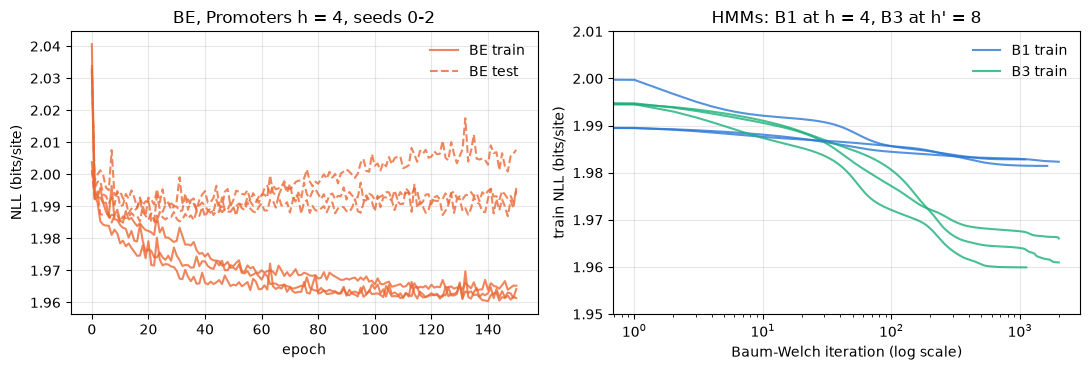

In [11]:
# live: training curves of the three seeds (BE per epoch, HMMs per EM iteration).
figure, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for seed in LIVE["seeds"]:
    history = live_histories[("BE", seed)]
    axes[0].plot([e["epoch"] for e in history], [e["evaluation"]["train"]["nll_bits_per_site"] for e in history],
                 color=STYLE["BE"]["color"], alpha=0.8, label="BE train" if seed == 0 else None)
    axes[0].plot([e["epoch"] for e in history], [e["evaluation"]["test"]["nll_bits_per_site"] for e in history],
                 color=STYLE["BE"]["color"], alpha=0.8, linestyle="--", label="BE test" if seed == 0 else None)
    for name in ("B1", "B3"):
        history = live_histories[(name, seed)]
        axes[1].plot([e["iteration"] for e in history], [e["evaluation"]["train"]["nll_bits_per_site"] for e in history],
                     color=STYLE[name]["color"], alpha=0.8, label=f"{name} train" if seed == 0 else None)
axes[0].set(xlabel="epoch", ylabel="NLL (bits/site)", title="BE, Promoters h = 4, seeds 0-2")
axes[1].set(xlabel="Baum-Welch iteration (log scale)", ylabel="train NLL (bits/site)", xscale="log", ylim=(1.95, 2.01),
            title=f"HMMs: B1 at h = 4, B3 at h' = {LIVE['matched_bond_dim']}")
for axis in axes:
    axis.grid(alpha=0.3)
    axis.legend(frameon=False)
plt.tight_layout()

**Observation.**
- The live seeds reproduce the stored values to round-off, or exactly.
  This confirms that the stored sweeps come from this code.
- On *train*, BE at $h=4$ beats the same-size HMM. The HMM with BE's
  parameter count ($h'=8$) matches it: its mean over the three seeds is
  about 0.001 bits/site lower.
- BE's test NLL stops improving long before its train NLL does.

**Inference.** The basic pipeline runs end to end and is deterministic. A
single cell cannot decide the claim; §7-§8 use all 10 seeds and all $h$.

**Remaining uncertainty.** Three seeds at one $h$; see the full sweeps
below.

**Claim impact.** None by itself. It validates the pipeline behind the
stored results.

## 7. Headline reproduction: Fig. 7 and Fig. 8 (stored, 960 runs)

*Faithful reproduction*: the paper's protocol and hyperparameters, all data,
$h=1..12$, 10 seeds per cell, in the paper's metric.
- **What is plotted:** the paper plots the best of 10 trials, with "best" =
  lowest train NLL (pre-declared). The faint dots are the individual seeds.
- **Paper points:** read at $h=1,4,8,12$ from the figure image, shown as
  hollow markers.
- **HMM:** ours is Baum-Welch run to convergence (up to 2000 iterations).

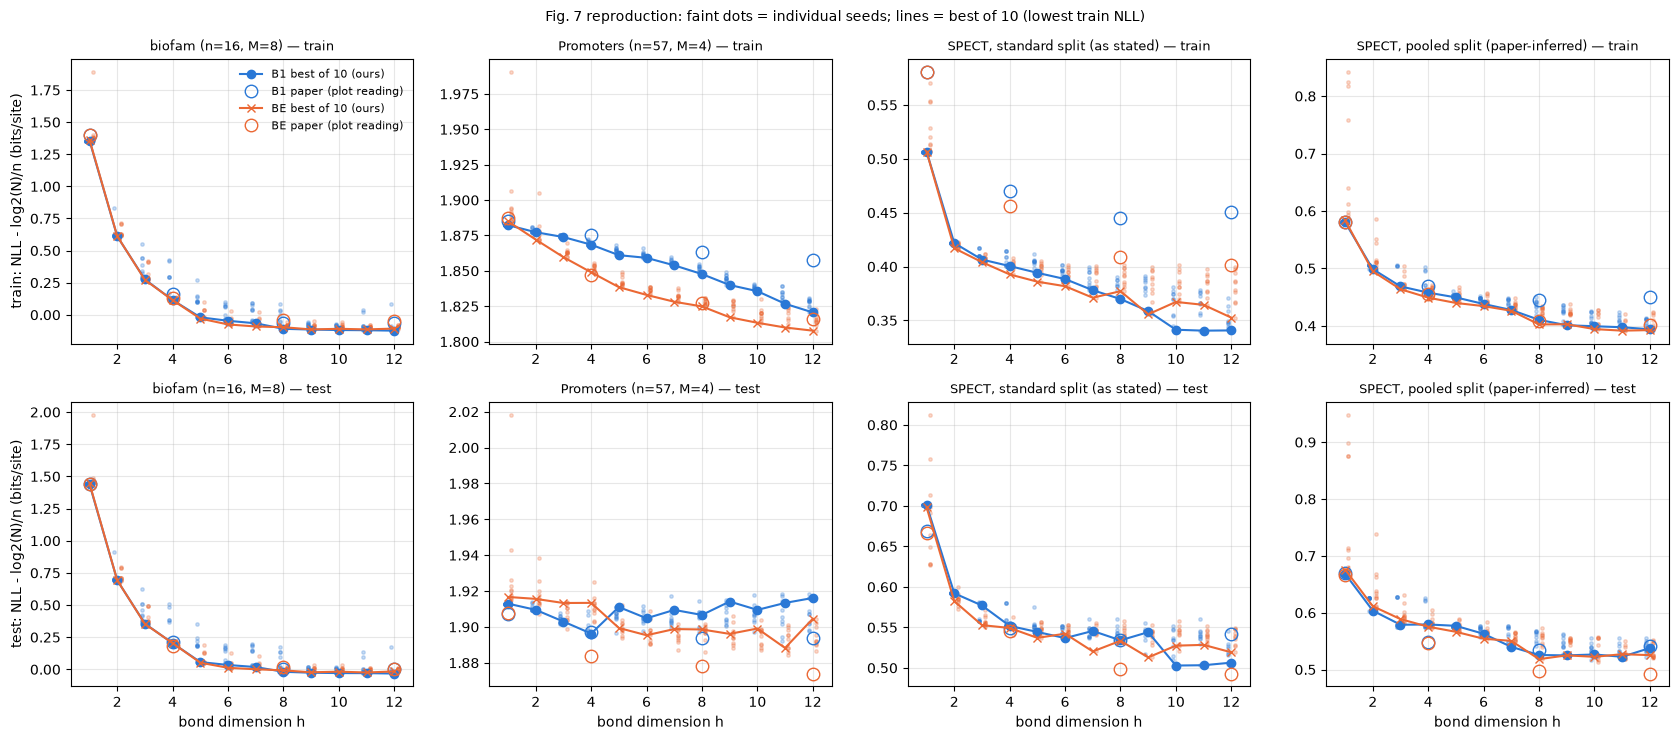

In [12]:
# stored: per-cell best-of-10 (lowest train NLL, ties within 1e-6 bits -> lowest seed) and all seeds.
def best_of_ten(frame: pd.DataFrame) -> pd.Series:
    lowest = frame.train_nll_bits_per_site.min()
    return frame[frame.train_nll_bits_per_site - lowest <= 1e-6].sort_values("seed").iloc[0]


valid3 = phase3[phase3.status == "valid"]
best = valid3.groupby(["arm", "label", "bond_dim"]).apply(best_of_ten, include_groups=False).reset_index()
PAPER_KEY = {"biofam": "biofam", "promoter_gene_sequences": "promoter_gene_sequences",
             "spect_heart": "spect_heart", "spect_heart_pooled": "spect_heart"}
figure, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for column, arm in enumerate(ARMS):
    for row, split in enumerate(("train", "test")):
        axis = axes[row][column]
        for label, model_key in (("B1", "hmm_baum_welch"), ("BE", "basis_enhanced")):
            style = STYLE[label]
            seeds = valid3[(valid3.arm == arm) & (valid3.label == label)]
            axis.scatter(seeds.bond_dim + (0.12 if label == "BE" else -0.12), seeds[f"{split}_paper_metric"],
                         s=6, color=style["color"], alpha=0.25)
            cell = best[(best.arm == arm) & (best.label == label)].sort_values("bond_dim")
            axis.plot(cell.bond_dim, cell[f"{split}_paper_metric"], color=style["color"], marker=style["marker"],
                      label=f"{label} best of 10 (ours)")
            paper = paper_values["fig7_best_of_ten"][PAPER_KEY[arm]][split][model_key]
            axis.plot([int(k) for k in paper], list(paper.values()), linestyle="none", marker="o", markersize=9,
                      markerfacecolor="none", markeredgecolor=style["color"], label=f"{label} paper (plot reading)")
        axis.set_title(f"{ARM_TITLE[arm]} — {split}", fontsize=9)
        axis.grid(alpha=0.3)
        if column == 0:
            axis.set_ylabel(f"{split}: NLL - log2(N)/n (bits/site)")
        if row == 1:
            axis.set_xlabel("bond dimension h")
axes[0][0].legend(frameon=False, fontsize=8)
figure.suptitle("Fig. 7 reproduction: faint dots = individual seeds; lines = best of 10 (lowest train NLL)", fontsize=10)
plt.tight_layout()

In [13]:
# stored: agreement of all 70 plotted paper items (results/paper_item_table.csv, utils/build_results_table.py).
items = pd.read_csv(RESULTS / "paper_item_table.csv")
items["group"] = items["Paper item"].str.extract(r"^(Fig\. \d+ [^,]+(?:, (?:train|test))?)")[0]
items["model"] = np.where(items["Paper item"].str.contains("Basis-enhanced"), "BE",
                          np.where(items["Paper item"].str.contains("HMM"), "HMM", "gap"))
pd.crosstab([items["group"], items["model"]], items["Metric agreement"])

Metric agreement                                         biofam offset (R12)  differs  match  within test-split spread
group                                             model                                                               
Fig. 7 Promoters, test                            BE                       0        3      1                         0
                                                  HMM                      0        2      2                         0
Fig. 7 Promoters, train                           BE                       0        0      4                         0
                                                  HMM                      0        2      2                         0
Fig. 7 SPECT pooled split (paper-inferred), test  BE                       0        0      1                         3
                                                  HMM                      0        0      3                         1
Fig. 7 SPECT pooled split (paper-inferred), train BE                       0        0      4                         0
                                                  HMM                      0        3      1                         0
Fig. 7 SPECT standard split (as stated), test     BE                       0        3      1                         0
                                                  HMM                      0        2      2                         0
Fig. 7 SPECT standard split (as stated), train    BE                       0        4      0                         0
                                                  HMM                      0        4      0                         0
Fig. 7 biofam, test                               BE                       0        0      1                         3
                                                  HMM                      0        0      2                         2
Fig. 7 biofam, train                              BE                       3        1      0                         0
                                                  HMM                      4        0      0                         0
Fig. 8 Promoters                                  gap                      0        3      0                         0
Fig. 8 SPECT pooled split (paper-inferred)        gap                      0        3      0                         0

In [14]:
# stored -> recomputed: Fig. 8 gap (bits per sequence) and the 5-sigma threshold (Wilks, df = h^2 - 1, LOG.md R7).
rows = []
for arm, paper_key in (("promoter_gene_sequences", "promoter_gene_sequences"), ("spect_heart_pooled", "spect_heart")):
    splits = SPLITS[(arm, "A")]
    for h in range(2, 13):
        lowest = {label: valid3[(valid3.arm == arm) & (valid3.label == label) & (valid3.bond_dim == h)]
                  .train_nll_bits_per_site.min() for label in ("BE", "B1")}
        gap = splits.sequence_length * (lowest["B1"] - lowest["BE"])
        threshold = likelihood_ratio_threshold_bits(len(splits.train), h * h - 1)
        rows.append({"arm": arm, "h": h, "gap ours": gap, "threshold": threshold, "5 sigma ours": gap > threshold,
                     "gap paper": paper_values["fig8_gap_bits_per_sequence"][paper_key].get(str(h)),
                     "threshold paper": paper_values["fig8_threshold_bits_per_sequence"][paper_key].get(str(h))})
fig8 = pd.DataFrame(rows)
# The paper's threshold curve was read only at even h; leave the decision empty where it was not read.
fig8["5 sigma paper"] = [None if pd.isna(t) else bool(g > t) for g, t in zip(fig8["gap paper"], fig8["threshold paper"])]
fig8

,arm,h,gap ours,threshold,5 sigma ours,gap paper,threshold paper,5 sigma paper
0,promoter_gene_sequences,2,0.2971,0.2997,False,0.25,0.30,False
1,promoter_gene_sequences,3,0.8091,0.4109,True,0.86,NaN,None
2,promoter_gene_sequences,4,1.1131,0.5381,True,1.59,0.54,True
3,promoter_gene_sequences,5,1.2874,0.6829,True,1.62,NaN,None
4,promoter_gene_sequences,6,1.4924,0.8456,True,1.69,0.85,True
5,promoter_gene_sequences,7,1.4657,1.0263,True,2.15,NaN,None
6,promoter_gene_sequences,8,1.3030,1.2251,True,2.05,1.23,True
7,promoter_gene_sequences,9,1.2980,1.4420,False,2.10,NaN,None
8,promoter_gene_sequences,10,1.2727,1.6769,False,2.53,1.69,True
9,promoter_gene_sequences,11,0.9565,1.9299,False,2.16,NaN,None


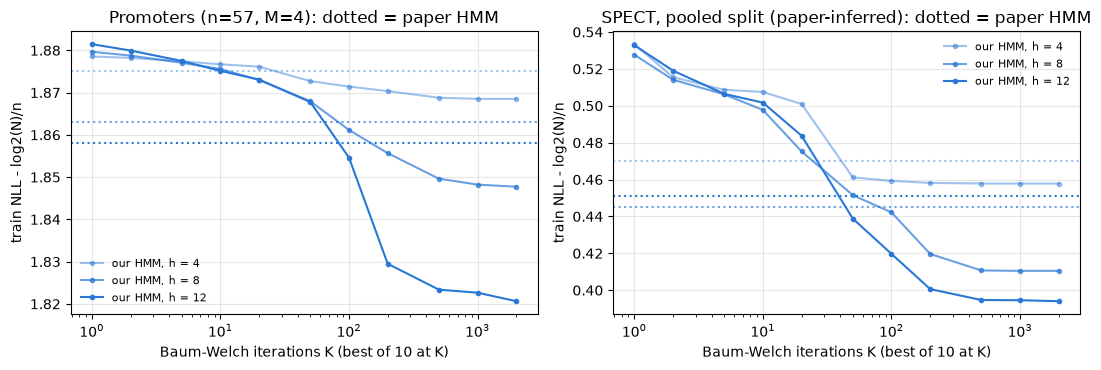

In [15]:
# stored: the paper's HMM points vs our HMM stopped after K Baum-Welch iterations (results/hmm_iteration_caps.json).
caps = json.loads((RESULTS / "hmm_iteration_caps.json").read_text())
figure, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for axis, (arm, sweep_index, paper_key) in zip(axes, (("promoter_gene_sequences", 0, "promoter_gene_sequences"),
                                                      ("spect_heart", 1, "spect_heart"))):
    for h, shade in ((4, 0.45), (8, 0.7), (12, 1.0)):
        cell = next(c for c in caps["sweeps"][sweep_index]["cells"] if c["dataset"] == arm and c["bond_dim"] == h)
        axis.plot(caps["caps"], [cell[f"train_at_{k}"] for k in caps["caps"]], color=STYLE["B1"]["color"],
                  alpha=shade, marker="o", markersize=3, label=f"our HMM, h = {h}")
        axis.axhline(paper_values["fig7_best_of_ten"][paper_key]["train"]["hmm_baum_welch"][str(h)],
                     color=STYLE["B1"]["color"], alpha=shade, linestyle=":")
    axis.set(xscale="log", xlabel="Baum-Welch iterations K (best of 10 at K)", ylabel="train NLL - log2(N)/n",
             title=f"{ARM_TITLE[arm if arm != 'spect_heart' else 'spect_heart_pooled']}: dotted = paper HMM")
    axis.grid(alpha=0.3)
    axis.legend(frameon=False, fontsize=8)
plt.tight_layout()

**Observation.**
- **BE matches the paper:** on Promoters and the pooled SPECT split, BE's
  best-of-10 training values agree with RMS 0.005 and 0.007 bits/site at
  $h=4,8,12$ (every BE train item is a *match*).
- **Our HMM does not:** the converged HMM is 0.007-0.057 bits/site
  *better* than the paper's, more so at larger $h$.
- **Why:** the paper's HMM points sit where our HMM is after about 100
  (Promoters) or 50 (SPECT) Baum-Welch iterations.
- **Consequence for Fig. 8:** the training gap shrinks. It is above the
  5σ threshold on Promoters only at $h=3$-8, and never on SPECT; the paper
  reports most $h$ on both.
- **Test values (split seed 0):** on pooled SPECT they are within 2 SD of
  the random-quarter spread (§10). On Promoters, BE's test values are
  0.021-0.031 above the paper at $h=4,8,12$, which is 6-9 times the
  Promoters split SD of 0.0035 at $h=1$; the unknown quarter alone does
  not explain them.

**Inference.** The paper's BE model is reproduced quantitatively. Its HMM
baseline looks under-trained, so part of the claimed separation is a
baseline artefact.

**Remaining uncertainty.** The paper's stopping rule, test quarters and
exact data versions are unknown.

**Claim impact.**
- *C3:* weakened. Reproduced on Promoters; not reproduced on SPECT against a
  converged HMM.
- *C4:* weakened (5σ only at $h=3$-8 on Promoters).
- §8 asks whether what is left survives fair baselines.

## 8. Fair baseline comparison (stored, 3,444 + 588 runs)

The paper's baseline differs from BE in more than "quantumness".

**How fair each control is**, dimension by dimension. "Matched" is used
only where the dimension really is matched.

| Dimension | B1 converged HMM | B2 gradient HMM | B3 HMM at $h'$ | B4 real BE | B5 k-gram |
|---|---|---|---|---|---|
| Information and inputs | same sequences, same integer coding | same | same | same | same |
| Parameter count | **not matched**: 2-6× fewer than BE | not matched (= B1) | **matched**: at least BE's count | fewer than BE (real) | not comparable (no $h$) |
| Training data | same split per protocol | same | same | same | same |
| Optimisation steps | EM to convergence (≤ 2000 iterations) | BE's minibatch, epochs, momentum | as B1 | as BE | closed form (counting) |
| Tuning budget | arm A: none (paper); arm B: same grid size, chosen on validation | arm A: lr chosen in arm B; arm B: same grid as BE | as B1 | arm A: paper $\alpha$; arm B: same grid as BE | smoothing on validation |
| Compute and wall time, median per run | 5 s (BE 40 s) | 6 s | 14 s at $h'>12$ | 29 s | < 0.01 s |
| Evaluation protocol | identical (split, metric, checkpoint rule per arm) | identical | identical | identical | identical |

- **Arm A, paper protocol:** answers "did the paper's comparison leave
  something out?"
- **Arm B, validation-tuned:** answers "does BE generalise better when
  every model gets the same tuning and early stopping?"
- **Selection:** hyperparameters were chosen on validation NLL only
  (`results/phase5_tuning_selection.json`). A setting with a failed run, or
  one that left the unitary group, was ineligible.

In [16]:
# stored: aggregate the per-seed results of every evidence sweep (valid runs only).
evidence = SEEDS[~SEEDS.sweep_id.str.startswith("phase5_tuning")]
valid = evidence[evidence.status == "valid"]
CELLS = (valid.groupby(["arm", "protocol", "label", "bond_dim", "order"], dropna=False)
         .agg(n=("seed", "size"), **{f"mean_{s}": (f"{s}_nll_bits_per_site", "mean") for s in ("train", "test")},
              **{f"sem_{s}": (f"{s}_nll_bits_per_site", "sem") for s in ("train", "test")})
         .reset_index())
CELLS[["sem_train", "sem_test"]] = CELLS[["sem_train", "sem_test"]].fillna(0.0)  # single deterministic B5 run
ALPHABET = {"biofam": 8, "promoter_gene_sequences": 4, "spect_heart": 2, "spect_heart_pooled": 2}


def cell(arm, protocol, label, h, order=None):
    frame = CELLS[(CELLS.arm == arm) & (CELLS.protocol == protocol) & (CELLS.label == label) & (CELLS.bond_dim == h)]
    frame = frame[frame.order.isna()] if order is None else frame[frame.order == order]
    return None if frame.empty else frame.iloc[0]


def matched_size(arm, h):
    return parameter_matched_hmm_bond_dim(free_parameter_count(h, ALPHABET[arm]), ALPHABET[arm])


def beats(x, y, split):
    # 2-SEM separation rule; None when a cell is missing.
    if x is None or y is None:
        return None
    return (y[f"mean_{split}"] - x[f"mean_{split}"]) > 2 * math.hypot(x[f"sem_{split}"], y[f"sem_{split}"])


def advantage_holds(arm, protocol, split, h):
    be = cell(arm, protocol, "BE", h)
    controls = [cell(arm, protocol, "B1", h), cell(arm, protocol, "B2", h),
                cell(arm, protocol, "B1", matched_size(arm, h))]  # B3 = Baum-Welch HMM at h'
    results = [beats(be, control, split) for control in controls]
    return None if any(r is None for r in results) else all(results)


def verdict(arm, protocol, split):
    holds = [advantage_holds(arm, protocol, split, h) for h in range(2, 13)]
    if any(r is None for r in holds):
        return "UNRESOLVED", [h for h, r in zip(range(2, 13), holds) if r]
    count = sum(holds)
    label = "SUPPORTED" if count >= 9 else "PARTIALLY_SUPPORTED" if count >= 3 else "UNSUPPORTED"
    return label, [h for h, r in zip(range(2, 13), holds) if r]


stored_verdicts = json.loads((RESULTS / "phase5_comparison.json").read_text())["verdicts"]
rows = []
for name, protocol, split in (("C3 learns better", "A", "train"), ("C3 generalizes better", "B", "test"),
                              ("C5 mean, test", "A", "test")):
    key = {"C3 learns better": "C3_learns_better_armA_train", "C3 generalizes better": "C3_generalizes_better_armB_test",
           "C5 mean, test": "C5_mean_armA_test"}[name]
    for arm in ARMS[1:]:
        label, hs = verdict(arm, protocol, split)
        stored_entry = next(v for v in stored_verdicts[key] if v["arm"] == arm)
        assert (label, hs) == (stored_entry["verdict"], stored_entry["advantage_holds_at_h"]), (name, arm)
        rows.append({"claim (rule)": name, "protocol": protocol, "split": split, "arm": arm,
                     "verdict": label, "BE beats B1, B2 and B3 at h": hs})
print("recomputed from per-seed metrics; identical to results/phase5_comparison.json")
pd.DataFrame(rows)

recomputed from per-seed metrics; identical to results/phase5_comparison.json


,claim (rule),protocol,split,arm,verdict,"BE beats B1, B2 and B3 at h"
0,C3 learns better,A,train,promoter_gene_sequences,UNSUPPORTED,[]
1,C3 learns better,A,train,spect_heart,UNSUPPORTED,[]
2,C3 learns better,A,train,spect_heart_pooled,UNSUPPORTED,[]
3,C3 generalizes better,B,test,promoter_gene_sequences,PARTIALLY_SUPPORTED,"[7, 9, 10, 11, 12]"
4,C3 generalizes better,B,test,spect_heart,UNSUPPORTED,[]
5,C3 generalizes better,B,test,spect_heart_pooled,UNSUPPORTED,[]
6,"C5 mean, test",A,test,promoter_gene_sequences,PARTIALLY_SUPPORTED,"[5, 6, 7, 8, 9, 10, 11, 12]"
7,"C5 mean, test",A,test,spect_heart,UNSUPPORTED,[]
8,"C5 mean, test",A,test,spect_heart_pooled,UNSUPPORTED,[]


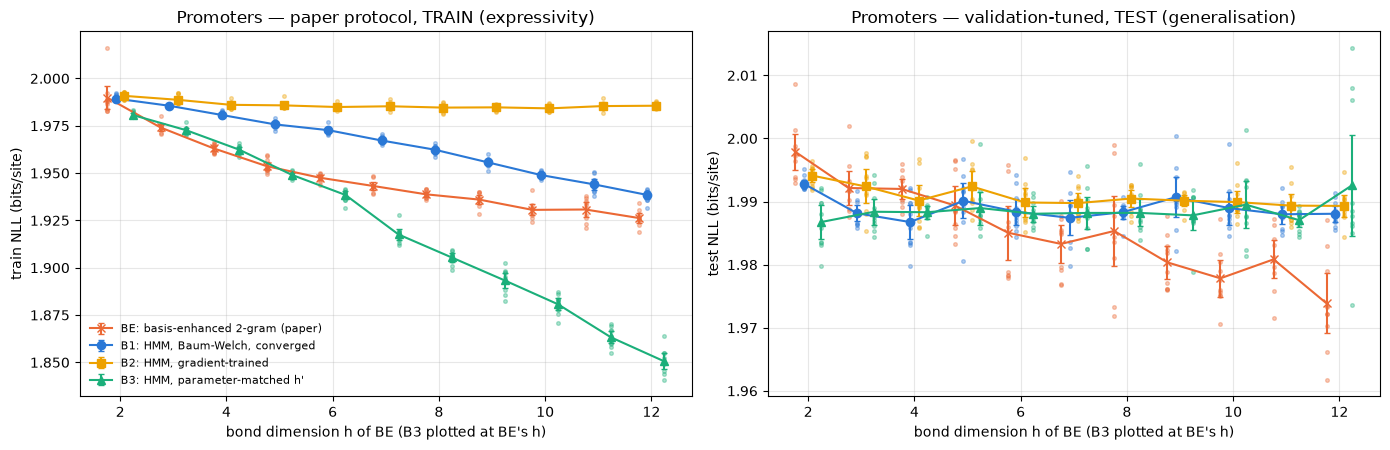

In [17]:
# stored: Promoters, the one data set with an advantage. Individual seeds + mean +- 2 SEM per model.
figure, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=False)
for axis, (protocol, split, title) in zip(axes, (("A", "train", "paper protocol, TRAIN (expressivity)"),
                                                 ("B", "test", "validation-tuned, TEST (generalisation)"))):
    arm = "promoter_gene_sequences"
    for offset, label in zip((-0.24, -0.08, 0.08, 0.24), ("BE", "B1", "B2", "B3")):
        style = STYLE[label]
        xs, means, errors = [], [], []
        for h in range(2, 13):
            size = matched_size(arm, h) if label == "B3" else h
            frame = valid[(valid.arm == arm) & (valid.protocol == protocol)
                          & (valid.label == ("B1" if label == "B3" else label)) & (valid.bond_dim == size)]
            axis.scatter(np.full(len(frame), h + offset), frame[f"{split}_nll_bits_per_site"],
                         s=7, color=style["color"], alpha=0.35)
            xs.append(h + offset)
            means.append(frame[f"{split}_nll_bits_per_site"].mean())
            errors.append(2 * frame[f"{split}_nll_bits_per_site"].sem())
        axis.errorbar(xs, means, yerr=errors, color=style["color"], marker=style["marker"], linestyle="-",
                      capsize=2, label=style["label"])
    axis.set(title=f"Promoters — {title}", xlabel="bond dimension h of BE (B3 plotted at BE's h)",
             ylabel=f"{split} NLL (bits/site)")
    axis.grid(alpha=0.3)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()

**Observation.**
- **Train, paper protocol:** on Promoters, BE beats the equal-size HMMs (B1,
  B2) at every $h\ge3$. But the HMM with as many parameters (B3) fits the
  training data *better* at $h=2$ and from $h=5$ on (at $h=12$: 1.851 vs
  1.926 bits/site).
- **Test, validation-tuned (split seed 0):** BE has a lower test NLL than
  all three HMM controls at $h=7,9,10,11,12$, by 0.004-0.019 bits/site. At
  $h=2$-6 and $h=8$ there is no such separation.
- **SPECT** (both splits) shows no advantage under either protocol.
- The recomputed verdicts are identical to the stored ones.

**Inference.**
- The "learns better" part of C3 is explained by parameter count: BE has
  more parameters than the HMM it was compared with.
- A small "generalises better" effect on Promoters beats every HMM
  control on this test quarter, with equal tuning and early stopping.

**Remaining uncertainty.** The held-out effect is measured on one test
quarter of 26 sequences; §10 repeats it on five other quarters.

**Claim impact.**
- C3 *learns better*: **not reproduced** once parameters are matched.
- C3 *generalises better*: **partially supported** on Promoters
  ($h=7,9$-12, split seed 0), **not supported** on SPECT.
- C5 (mean, paper protocol, test): partially supported on Promoters
  ($h=5$-12).

## 9. Controls and ablations

Three controls separate the paper's explanation from alternatives:

1. **Complex amplitudes (Sec. VI).** B4 is BE restricted to real orthogonal
   matrices, with everything else unchanged. If the gap comes from quantum
   interference, BE should beat B4.
2. **Training algorithm.** B2 trains the HMM with BE's minibatch optimiser.
   If Baum-Welch were handicapping the HMM, B2 would do better than B1.
3. **Parameter count for the 5σ test (C4).** The Fig. 8 significance
   counts only where BE's best-of-10 train is also below B3's.

In [18]:
# stored -> recomputed: Sec. VI (BE beats B4 on arm A train AND arm B test), B2 vs B1, and C4.
rows = []
for arm in ARMS:
    holds, missing = [], []
    for h in range(2, 13):
        a = beats(cell(arm, "A", "BE", h), cell(arm, "A", "B4", h), "train")
        b = beats(cell(arm, "B", "BE", h), cell(arm, "B", "B4", h), "test")
        if a is None or b is None:
            missing.append(h)
        elif a and b:
            holds.append(h)
    rows.append({"arm": arm, "BE beats B4 (train A and test B) at h": holds, "missing h": missing,
                 "verdict (>= 3 h)": "SUPPORTED" if len(holds) >= 3 else
                 ("UNRESOLVED" if len(holds) + len(missing) >= 3 else "UNSUPPORTED")})
display(pd.DataFrame(rows))

b2_rows = []
for arm in ARMS:
    for protocol in ("A", "B"):
        for split in ("train", "test"):
            results = [(beats(cell(arm, protocol, "B1", h), cell(arm, protocol, "B2", h), split),
                        beats(cell(arm, protocol, "B2", h), cell(arm, protocol, "B1", h), split)) for h in range(2, 13)]
            b2_rows.append({"arm": arm, "protocol": protocol, "split": split,
                            "B1 better than B2 (h count)": sum(bool(r[0]) for r in results),
                            "B2 better than B1 (h count)": sum(bool(r[1]) for r in results)})
b2 = pd.DataFrame(b2_rows)
print(f"B2 vs B1 over {len(b2) * 11} matched cells: B1 better in {b2.iloc[:, 3].sum()}, "
      f"B2 better in {b2.iloc[:, 4].sum()}")

c4 = []
for h in range(2, 13):
    arm = "promoter_gene_sequences"
    be_best = valid[(valid.arm == arm) & (valid.protocol == "A") & (valid.label == "BE") & (valid.bond_dim == h)].train_nll_bits_per_site.min()
    b3_best = valid[(valid.arm == arm) & (valid.protocol == "A") & (valid.label == "B1")
                    & (valid.bond_dim == matched_size(arm, h))].train_nll_bits_per_site.min()
    five = bool(fig8[(fig8.arm == arm) & (fig8.h == h)]["5 sigma ours"].iloc[0])
    c4.append({"h": h, "h'": matched_size(arm, h), "5 sigma vs B1": five, "BE best train": be_best,
               "B3 best train": b3_best, "BE below B3": be_best < b3_best, "C4 counts": five and be_best < b3_best})
print("C4 on Promoters (Fig. 8 gap must also survive parameter matching):")
pd.DataFrame(c4)

,arm,BE beats B4 (train A and test B) at h,missing h,verdict (>= 3 h)
0,biofam,[],[2],UNSUPPORTED
1,promoter_gene_sequences,[3],[],UNSUPPORTED
2,spect_heart,[],[],UNSUPPORTED
3,spect_heart_pooled,[],[],UNSUPPORTED


B2 vs B1 over 176 matched cells: B1 better in 111, B2 better in 0
C4 on Promoters (Fig. 8 gap must also survive parameter matching):


,h,h',5 sigma vs B1,BE best train,B3 best train,BE below B3,C4 counts
0,2,4,False,1.9830,1.9794,False,False
1,3,6,True,1.9706,1.9701,False,False
2,4,8,True,1.9599,1.9586,False,False
3,5,10,True,1.9494,1.9466,False,False
4,6,12,True,1.9439,1.9316,False,False
5,7,15,True,1.9391,1.9121,False,False
6,8,17,True,1.9358,1.8987,False,False
7,9,19,False,1.9281,1.8822,False,False
8,10,21,False,1.9242,1.8710,False,False
9,11,24,False,1.9209,1.8552,False,False


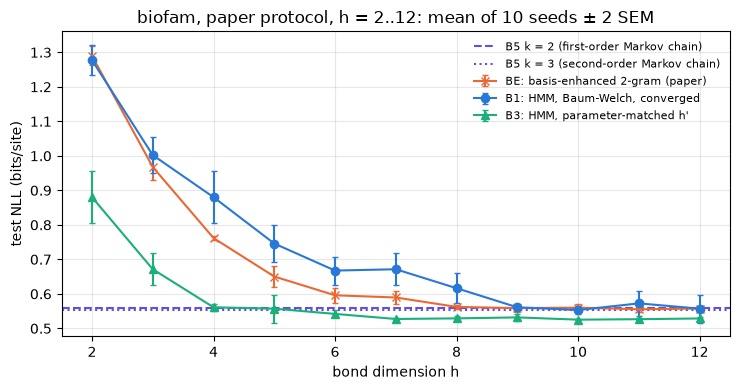

In [19]:
# stored: biofam, where the paper expects "comparable". BE vs the k-gram references (arm A, test).
arm = "biofam"
figure, axis = plt.subplots(figsize=(7.5, 4))
for label in ("BE", "B1", "B3"):
    xs = list(range(2, 13))
    rows = [cell(arm, "A", "B1" if label == "B3" else label, matched_size(arm, h) if label == "B3" else h) for h in xs]
    axis.errorbar(xs, [r["mean_test"] for r in rows], yerr=[2 * r["sem_test"] for r in rows], color=STYLE[label]["color"],
                  marker=STYLE[label]["marker"], capsize=2, label=STYLE[label]["label"])
for order, line in ((2, "--"), (3, ":")):
    axis.axhline(cell(arm, "A", "B5", 0, order)["mean_test"], color=STYLE["B5"]["color"], linestyle=line,
                 label=f"B5 k = {order} ({'first' if order == 2 else 'second'}-order Markov chain)")
axis.set(xlabel="bond dimension h", ylabel="test NLL (bits/site)",
         title="biofam, paper protocol, h = 2..12: mean of 10 seeds ± 2 SEM")
axis.grid(alpha=0.3)
axis.legend(frameon=False, fontsize=8)
plt.tight_layout()

**Observation.**
- **Complex amplitudes:** BE beats its real-amplitude version on both
  arm A train and arm B test only at Promoters $h=3$. On Promoters BE
  beats B4 on train at $h=3$-10, but on held-out data only at $h=2,3,12$.
- **Training algorithm:** the gradient-trained HMM is never better than
  Baum-Welch.
- **C4:** the Fig. 8 5σ gap survives parameter matching at no $h$.
- **biofam:** a first-order Markov chain beats BE up to $h=7$ and ties it
  beyond.
  BE is clearly better than the equal-size HMM at $h=4$-8, but clearly
  worse than the parameter-matched one at $h=4$-7. So "comparable" holds in
  neither direction under the 0.05 bits/site rule.

**Inference.**
- The ablation does not show that complex amplitudes cause the Promoters
  held-out advantage: B4 is not separated from BE there at most $h$.
- The train gap between BE and B4 is confounded: B4 has only 53-67% of
  BE's parameters.
- The training-gap significance is a parameter-count effect.
- The paper's choice of Baum-Welch did not weaken its baseline.

**Remaining uncertainty.**
- B4 has fewer parameters than BE, so "complex amplitudes" and "more
  parameters" are not fully separated.
- A real model with BE's parameter count was not run.

**Claim impact.**
- Sec. VI: *not supported* (at most one $h$ on any data set).
- C4: *not supported* after parameter matching.
- biofam "comparable": *not confirmed* by the mean-based rule.

## 10. Robustness and uncertainty

In [20]:
# live: how much does the unknown random test quarter move the metric? Closed-form h = 1 model over 20 split seeds.
rows = []
for arm, config in (("promoter_gene_sequences", "e5_fig7_promoters_original"),
                    ("spect_heart_pooled", "e5_fig7_spect_pooled_original"), ("biofam", "e5_fig7_biofam_original")):
    values = []
    for split_seed in range(20):
        splits = load_splits(config_for(config, dataset__split_seed=split_seed))
        nll = iid_nll_bits(splits.train, splits.test, splits.alphabet_size)
        values.append(paper_kl_estimate_bits_per_site(nll, len(splits.test), splits.sequence_length))
    rows.append({"arm": arm, "test quarter size": len(splits.test), "h=1 test metric, mean over 20 splits": np.mean(values),
                 "SD over splits": np.std(values, ddof=1), "split-seed-0 value": values[0]})
pd.DataFrame(rows)

,arm,test quarter size,"h=1 test metric, mean over 20 splits",SD over splits,split-seed-0 value
0,promoter_gene_sequences,26,1.9127,0.0035,1.9130
1,spect_heart_pooled,66,0.6542,0.0189,0.6685
2,biofam,500,1.4599,0.0219,1.4395


400 runs, statuses {'COMPLETED': 400}, excluded 0
advantage holds in 8 of 10 (split, h) cells -> split-robust


,split seed,h,BE mean test,BE advantage over B1 (2-SEM margin),BE advantage over B2 (2-SEM margin),BE advantage over B3 (2-SEM margin),"BE beats B1, B2, B3"
0,1,8,1.9823,+0.0107 (0.0044),+0.0118 (0.0037),+0.0088 (0.0037),True
1,1,12,1.9812,+0.0101 (0.0058),+0.0096 (0.0049),+0.0098 (0.0056),True
2,2,8,1.9794,+0.0087 (0.0038),+0.0093 (0.0029),+0.0082 (0.0032),True
3,2,12,1.9773,+0.0083 (0.0043),+0.0108 (0.0037),+0.0093 (0.0050),True
4,3,8,1.9803,+0.0080 (0.0055),+0.0097 (0.0049),+0.0232 (0.0107),True
5,3,12,1.9733,+0.0195 (0.0069),+0.0156 (0.0045),+0.0506 (0.0167),True
6,4,8,1.9803,+0.0019 (0.0026),+0.0042 (0.0033),+0.0044 (0.0067),False
7,4,12,1.9822,-0.0001 (0.0041),+0.0022 (0.0039),+0.0014 (0.0034),False
8,5,8,1.9820,+0.0057 (0.0040),+0.0071 (0.0038),+0.0087 (0.0058),True
9,5,12,1.9786,+0.0130 (0.0068),+0.0109 (0.0039),+0.0097 (0.0081),True


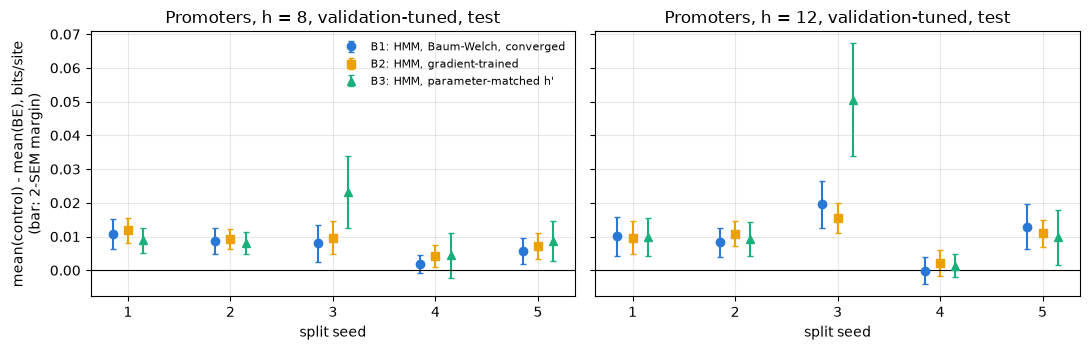

In [21]:
# stored: split-seed check (extension, rule declared in LOG.md before the runs). Promoters, validation-tuned
# protocol, split seeds 1-5, h = 8 and 12, 10 seeds per model, hyperparameters selected on split seed 0.
robust = json.loads((RESULTS / "robustness_split_seeds_summary.json").read_text())
robust_runs = pd.read_csv(RESULTS / "robustness_split_seeds_runs.csv")
print(f"{len(robust_runs)} runs, statuses {robust_runs.status.value_counts().to_dict()}, excluded {robust['excluded_runs']}")
table = pd.DataFrame([{
    "split seed": d["split_seed"], "h": d["h"], "BE mean test": d["BE_mean_test"],
    **{f"BE advantage over {b} (2-SEM margin)": f"{d[f'BE_advantage_over_{b}']:+.4f} ({d[f'margin_{b}']:.4f})"
       for b in ("B1", "B2", "B3")},
    "BE beats B1, B2, B3": d["BE_beats_B1_B2_B3"]} for d in robust["decisions"]])
held = int(table["BE beats B1, B2, B3"].sum())
label = "split-robust" if held >= 8 else "split-dependent" if held >= 3 else "not reproduced on other splits"
print(f"advantage holds in {held} of {len(table)} (split, h) cells -> {label}")
display(table)

figure, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for axis, h in zip(axes, (8, 12)):
    rows = [d for d in robust["decisions"] if d["h"] == h]
    for offset, baseline in zip((-0.15, 0.0, 0.15), ("B1", "B2", "B3")):
        axis.errorbar([d["split_seed"] + offset for d in rows], [d[f"BE_advantage_over_{baseline}"] for d in rows],
                      yerr=[d[f"margin_{baseline}"] for d in rows], fmt=STYLE[baseline]["marker"],
                      color=STYLE[baseline]["color"], capsize=2, label=STYLE[baseline]["label"])
    axis.axhline(0, color="black", linewidth=0.8)
    axis.set(xlabel="split seed", title=f"Promoters, h = {h}, validation-tuned, test")
    axis.grid(alpha=0.3)
axes[0].set_ylabel("mean(control) - mean(BE), bits/site\n(bar: 2-SEM margin)")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()

In [22]:
# stored: incomplete coverage and invalid runs (never silently dropped).
coverage = (SEEDS.groupby(["sweep_id", "status"]).size().unstack(fill_value=0)
            .assign(planned=lambda frame: frame.sum(axis=1)))
display(coverage)
problems = SEEDS[SEEDS.status != "valid"]
problems.groupby(["sweep_id", "arm", "protocol", "label", "bond_dim", "hparams", "status"]).seed.apply(list).reset_index()

status,failed,invalid,valid,planned
sweep_id,,,,
e5_fig7_20261113-101421,0,0,720,720
e5_fig7_spect_pooled_20261113-114428,0,0,240,240
e5_merlin_20261112-132728,0,0,360,360
e5_merlin_spect_pooled_20261112-164320,0,0,120,120
phase5_finals_20261113-134830,27,3,3414,3444
phase5_tuning_20261113-124847,3,1,584,588


,sweep_id,arm,protocol,label,bond_dim,hparams,status,seed
0,phase5_finals_20261113-134830,biofam,B,B4,1,"{""lr"": 0.01}",failed,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]"
1,phase5_finals_20261113-134830,biofam,B,B4,2,"{""lr"": 0.01}",failed,"[1, 2, 3, 4, 6, 7, 9]"
2,phase5_finals_20261113-134830,biofam,B,B4,2,"{""lr"": 0.01}",invalid,"[0, 5, 8]"
3,phase5_finals_20261113-134830,biofam,B,BE,1,"{""lr"": 0.003}",failed,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]"
4,phase5_tuning_20261113-124847,biofam,B,B4,4,"{""lr"": 0.03}",failed,"[0, 2]"
5,phase5_tuning_20261113-124847,biofam,B,B4,4,"{""lr"": 0.03}",invalid,[1]
6,phase5_tuning_20261113-124847,biofam,B,BE,4,"{""lr"": 0.03}",failed,[2]


In [23]:
# stored: tuning — every candidate's mean validation NLL; '*' marks the selected value (validation only).
selection = json.loads((RESULTS / "phase5_tuning_selection.json").read_text())
rows = []
for entry in selection["selections"]:
    if entry["model"] == "kgram_counting":
        continue
    row = {"arm": entry["arm"], "model": LABEL[entry["model"]]}
    for candidate in entry["candidates"]:
        score = candidate["mean_validation_nll_bits_per_site"]
        mark = "*" if candidate["value"] == entry["selected"] else ""
        column = f"{entry['hyperparameter']} = {candidate['value']:g}"
        row[column] = "ineligible" if not candidate["eligible"] else f"{score:.4f}{mark}"
    rows.append(row)
tuning = pd.DataFrame(rows).fillna("")
lr_columns = [c for c in tuning.columns if c.startswith("lr")]
pseudo_columns = [c for c in tuning.columns if c.startswith("pseudo_count")]
display(tuning[tuning.model != "B1"][["arm", "model", *lr_columns]])
tuning[tuning.model == "B1"][["arm", "model", *pseudo_columns]]

,arm,model,lr = 0.001,lr = 0.003,lr = 0.01,lr = 0.03
0,biofam,BE,0.6499,0.6319*,0.6314,ineligible
1,biofam,B4,0.6505,0.6421,0.6343*,ineligible
3,biofam,B2,0.9114,0.7997,0.7687,0.7335*
4,promoter_gene_sequences,BE,1.9847,1.9817,1.9761,1.9730*
5,promoter_gene_sequences,B4,1.9851,1.9834,1.9812,1.9789*
7,promoter_gene_sequences,B2,1.9896,1.9876,1.9857*,1.9848
8,spect_heart_pooled,BE,0.8075,0.7921,0.7804,0.7743*
9,spect_heart_pooled,B4,0.8005,0.7869,0.7772,0.7740*
11,spect_heart_pooled,B2,0.8816,0.8536,0.8371,0.8056*
12,spect_heart,BE,0.7301,0.7108,0.7074,0.6988*


,arm,model,pseudo_count = 0,pseudo_count = 0.001,pseudo_count = 0.01
2,biofam,B1,0.7063*,0.7064,0.7068
6,promoter_gene_sequences,B1,1.9844*,1.9844,1.9846
10,spect_heart_pooled,B1,0.7852,0.7846,0.7824*
14,spect_heart,B1,0.7117,0.7114,0.7077*


**Observation.**
- **Test-split spread:** the unknown test quarter alone moves the metric
  by a standard deviation of about 0.003 (Promoters) and about 0.02 (SPECT,
  biofam), at $h=1$.
- **Split-seed check (Promoters):** on five other random
  quarters (split seeds 1-5) at $h=8$ and 12, BE beats B1, B2 and B3 in 8
  of 10 cells, by 0.006-0.016 bits/site over the best control where it
  holds. Split seed 4 shows no separation at either $h$.
- **Coverage:** the four reproduction and MerLin sweeps are complete. In
  the comparison sweeps, all failed and invalid runs sit at biofam,
  validation-tuned, BE and B4:
  - *finals:* 27 failed and 3 invalid (BE $h=1$; B4 $h=1$-2);
  - *tuning:* 3 failed and 1 invalid, at $h=4$, $\alpha=0.03$.
  These runs diverged or left the unitary group (the likelihood is no
  longer normalised). They are listed, and excluded from every mean.
- **Tuning grid edge:** several selected learning rates are at the top of
  the grid (0.03), for BE as for B2.
- **Ties:** values within $10^{-3}$ bits of the best tie and go to the
  paper value. That is why Promoters B2 uses 0.01 (tied with 0.03) and the
  Baum-Welch pseudo-count stays 0 where all three values tie.

**Inference.** The conclusions on Promoters and SPECT use complete cells.
The biofam validation-tuned arm has no BE evidence at $h=1$ and no B4
evidence at $h=1$-2, which does not affect any decision (biofam's rule
uses $h\ge4$). The Promoters
held-out advantage is not an artefact of split seed 0: it recurs on 4 of
5 other quarters, which meets the pre-declared *split-robust* label
exactly at its threshold (8 of 10).

**Remaining uncertainty.**
- The split-seed check covers Promoters at $h=8$ and 12 only, with the
  hyperparameters selected on split seed 0.
- The learning-rate optimum may lie above 0.03.

**Claim impact.** None of the frozen Phase 5 verdicts
changes (they stay on split seed 0). The extension check labels the
Promoters held-out effect *split-robust* at the threshold, with one
quarter showing no advantage.

## 11. Photonic assessment (extension, simulated with MerLin)

**Status: `PARTIAL_MERLIN_TRANSLATION`.** This is an *adaptation*, not the
paper's model.

The role to preserve is a coherent memory of dimension $h$ that emits one
symbol per site. The minimal linear-optical version, a heralded two-photon
"photonic quantum HMM", works as follows:
- one photon spread over $h$ hidden modes is the memory;
- at each site a probe photon enters mode $h$, and one shared trainable
  mesh $U$ acts on $h+M$ modes;
- detecting exactly one photon in the $M$ data modes heralds the symbol
  $m$, and the hidden photon stays coherent for the next site.

The heralded maps are two-photon permanents:

$$K_m = U_{h+m,h}\,W + U_{:h,h}\,U_{h+m,:h},\qquad W=U_{:h,:h},$$

and the model is post-selected on all $n$ heralds:

$$q(x)=\frac{\lVert K_{x_n}\cdots K_{x_1}\psi_0\rVert^2}{Z},$$

where $Z$ is the herald success probability, computed exactly.

In [24]:
# live: a small MerLin model (h = 6, M = 8, as biofam): normalisation, herald success, and the memory limit.
from quantum_correlations_generative_models.lib.photonic_hmm_merlin import PhotonicQuantumHMM  # noqa: E402

h, M, n = 6, 8, 3
photonic = PhotonicQuantumHMM(bond_dim=h, alphabet_size=M, seed=0)
sequences = torch.tensor(list(itertools.product(range(M), repeat=n)))
with torch.no_grad():
    kraus = photonic.kraus_operators()  # K[m, b, a]
    total = photonic.log_prob(sequences).exp().sum().item()
    success_bits = photonic.log_herald_success(kraus, n).item() / math.log(2)
    memory = torch.randn(h, dtype=torch.complex128, generator=torch.Generator().manual_seed(1))
    successors = torch.stack([kraus[m] @ memory for m in range(M)])  # the M possible memories after one symbol
print(f"modes h+M = {photonic.num_modes}, photons = 2, trainable parameters = {photonic.trainable_parameter_count()}")
print(f"total probability over all {M}^{n} sequences: {total:.12f}")
print(f"log2 herald success for n = {n}: {success_bits:.2f}")
print(f"rank of each heralded map K_m: {[int(torch.linalg.matrix_rank(kraus[m])) for m in range(M)]}")
print(f"dimension spanned by the {M} post-emission memories K_m psi of one memory psi: "
      f"{int(torch.linalg.matrix_rank(successors))} (an HMM or BE with h = {h} can reach up to {min(h, M)})")

modes h+M = 14, photons = 2, trainable parameters = 194
total probability over all 8^3 sequences: 1.000000000000
log2 herald success for n = 3: -1.64
rank of each heralded map K_m: [6, 6, 6, 6, 6, 6, 6, 6]
dimension spanned by the 8 post-emission memories K_m psi of one memory psi: 2 (an HMM or BE with h = 6 can reach up to 6)


In [25]:
# stored: MerLin (arm A, 10 seeds) against the equal-h HMM and the HMM matched to MerLin's parameter count.
merlin = json.loads((RESULTS / "phase5_comparison.json").read_text())["verdicts"]["MerLin_armA"]
photonic_rows = json.loads((RESULTS / "photonic_comparison.json").read_text())["rows"]
herald = pd.DataFrame(photonic_rows).groupby("arm").agg(
    herald_log2_min=("herald_success_log2_min", "min"), herald_log2_max=("herald_success_log2_max", "max"),
    cpu_hours=("wall_seconds_total", lambda s: s.sum() / 3600))
summary = pd.DataFrame([{"arm": m["arm"], "MerLin beats B1 (train)": m["MerLin_beats_B1_train_at_h"],
                         "MerLin beats B1 (test)": m["MerLin_beats_B1_test_at_h"],
                         "matched HMM beats MerLin (train)": len(m["B3_merlin_beats_MerLin_train_at_h"]),
                         "matched HMM beats MerLin (test)": len(m["B3_merlin_beats_MerLin_test_at_h"])} for m in merlin])
summary.set_index("arm").join(herald)

,MerLin beats B1 (train),MerLin beats B1 (test),matched HMM beats MerLin (train),matched HMM beats MerLin (test),herald_log2_min,herald_log2_max,cpu_hours
arm,,,,,,,
biofam,[],[],12,12,-34.9655,-1.6703,15.7470
promoter_gene_sequences,[],[],12,10,-188.9211,-10.4560,2.1125
spect_heart,[5],[],12,10,-99.6974,-1.4404,1.0546
spect_heart_pooled,[2],[2],12,12,-103.7994,-5.6020,2.7182


**Hardware-aware settings:**
- *Space and detection:* `ComputationSpace.FOCK`, ideal
  photon-number-resolving detectors on the data modes.
- *Size:* 2 photons, $h+M$ = 3-20 modes.
- *Post-selection:* global, on every site.
- *Simulation:* MerLin 0.4.1, exact, shots = 0, float64, no loss.
- *Training:* Adam, learning rate 0.01, not tuned.

**Observation.**
- The model is exactly normalised, and each heralded map $K_m$ is full
  rank. But from any given memory $\psi$, the $M$ possible next memories
  $K_m\psi$ all lie in one two-dimensional plane, spanned by $W\psi$ and
  the probe column $U_{:h,h}$, because every symbol shares them.
- So one emission can write only "one complex number's worth" of
  information about the symbol into the memory, whatever $h$ is. A larger
  $h$ adds parameters but no memory of the past.
- Against the converged HMM and the HMM matched to its parameter count
  (partially commensurable: MerLin is simulated and untuned), MerLin wins
  only at isolated points (about 2 such
  flags are expected by chance among 96 comparisons). The HMM matched to
  its parameter count beats it on train at every $h$.
- Herald success per Promoters sequence (57 symbols) falls to $2^{-124}$
  (mean over seeds at the worst $h$; single seeds reach $2^{-189}$).

**Inference.** The minimal photonic memory does not preserve the scaling
with $h$ that gives BE its capacity.

**Remaining uncertainty.** Richer mappings (several probe photons, or
symbol-dependent meshes) could lift the rank-2 limit at a higher herald
cost; they were not run.

**Claim impact.** Extension verdict: *no photonic advantage* for this
mapping.

## 12. Conclusion

**Five separate questions.**

| Question | Answer | Evidence |
|---|---|---|
| Does the software execute? | Yes; live runs reproduce stored values | §6 |
| Does the method solve the task (fit the data)? | Yes; BE learns all three data sets | §6, §7 |
| Does the paper's metric reproduce? | Yes for BE (RMS 0.005-0.007 bits/site on train); the paper's HMM is under-trained | §2.1, §7 |
| Does the paper's explanation survive controls? | No: the training gap is a parameter-count effect, and the real-amplitude ablation does not single out complex amplitudes | §8, §9 |
| Does the method beat a fair baseline? | Only on Promoters held-out data at $h=7,9$-12 (0.004-0.019 bits/site) on the paper-style test quarter; it recurs on 4 of 5 other random splits | §8, §10 |

**1. What reproduced.**
- Theorem 1 and App. E, F (exact) and the ingredients of Theorem 2 (§4).
- The BE model's Fig. 7 training values (§7).
- The Promoters 5σ training gap at $h=3$-8 against a converged HMM (§7).
- A held-out advantage on Promoters over every HMM control at $h=7,9$-12
  on split seed 0 (§8). It recurs on 4 of 5 other random test
  quarters at $h=8$ and 12 (8 of 10 cells) (§10).

**2. What did not reproduce.**
- The SPECT advantage, on either split, against any control (§7, §8).
- The 5σ significance on SPECT, and on Promoters at $h\ge9$ (§7).
- "Learns better" once parameter count is matched (§8).
- The 5σ gap once parameter count is matched (§9).
- The Sec. VI attribution to complex amplitudes (§9).
- biofam "comparable" under the mean rule (§9).

**3. What remains unresolved.**
- Whether a real-amplitude model matched in parameters would also fall
  short of BE on Promoters train (§9).
- The paper's exact HMM stopping rule, test quarters and biofam data
  version (§7).

**4. What was not attempted.**
- Theorem 3 (complexity-theoretic).
- The asymptotic bound of Theorem 2.
- Hardware runs.
- Learning rates above 0.03.
- A real-amplitude model matched in parameters.
- Richer photonic mappings.

**5. Reproduction verdict: partially reproduced.**
- The theory and the model reproduce.
- The empirical advantage claimed in Fig. 7 rests largely on an
  under-trained HMM and on unmatched parameter counts.
- What survives is a small held-out advantage on Promoters at large $h$
  (§8, §10); the ablation does not attribute it to complex amplitudes.

**6. Extension verdict.** The minimal two-photon heralded MerLin adaptation
(simulated) shows no advantage over the converged or parameter-matched
HMMs. Its memory is
limited to two dimensions by construction, and its herald cost grows
exponentially with sequence length (§11).

**Limitations.**
- Paper values are plot readings.
- One split per data set; the SPECT split is inferred.
- The biofam validation-tuned arm lacks BE at $h=1$ and B4 at $h=1$-2
  (27 failed, 3 invalid runs).
- Several tuned learning rates sit at the grid edge.
- The MerLin adaptation is simulated with ideal components and an untuned
  learning rate.

Full records: `README.md`, `LOG.md`, `INSIGHTS.md`.